# 04 · Gradient clipping

**The question.** Practitioners often say that gradient clipping is non-negotiable for likelihood losses such as Tweedie
(claim 3 in notebook 01). The reasoning:
a Tweedie gradient grows with the size of the target, so one promo week in a batch can produce a gradient many times the median
size, and a single step that large can throw the weights far from where they were. This notebook looks at the mechanism on a tiny
model, then at the full model at the recipe's settings, then under three stressors.

In [1]:
import sys, os
try: import m5knobs  # noqa: F401  (installed with pip install -e .)
except ImportError: sys.path.insert(0, os.path.abspath(".."))  # run from notebooks/
from m5knobs import data, paths, results, experiments
from m5knobs.figures import toy, stress
results.check_available()  # stops with instructions if results/ is missing

## The mechanism, on two weights

Clipping rescales the gradient when its norm is above a threshold and keeps its direction, so it caps the length of a step.
AutoClip sets the threshold each step to a low percentile of the norms seen so far in the fit.

The toy is a real fit: a Tweedie GLM with two weights, `log mu = a + b * log1p(last week's sales)`, on M5 item-weeks. It is trained
twice by plain gradient descent from the same start on the same mini-batches; the only difference is AutoClip. Left: the path of
the two weights over the loss surface. Right: gradient norm with the clip threshold, and the full-data loss, per step.

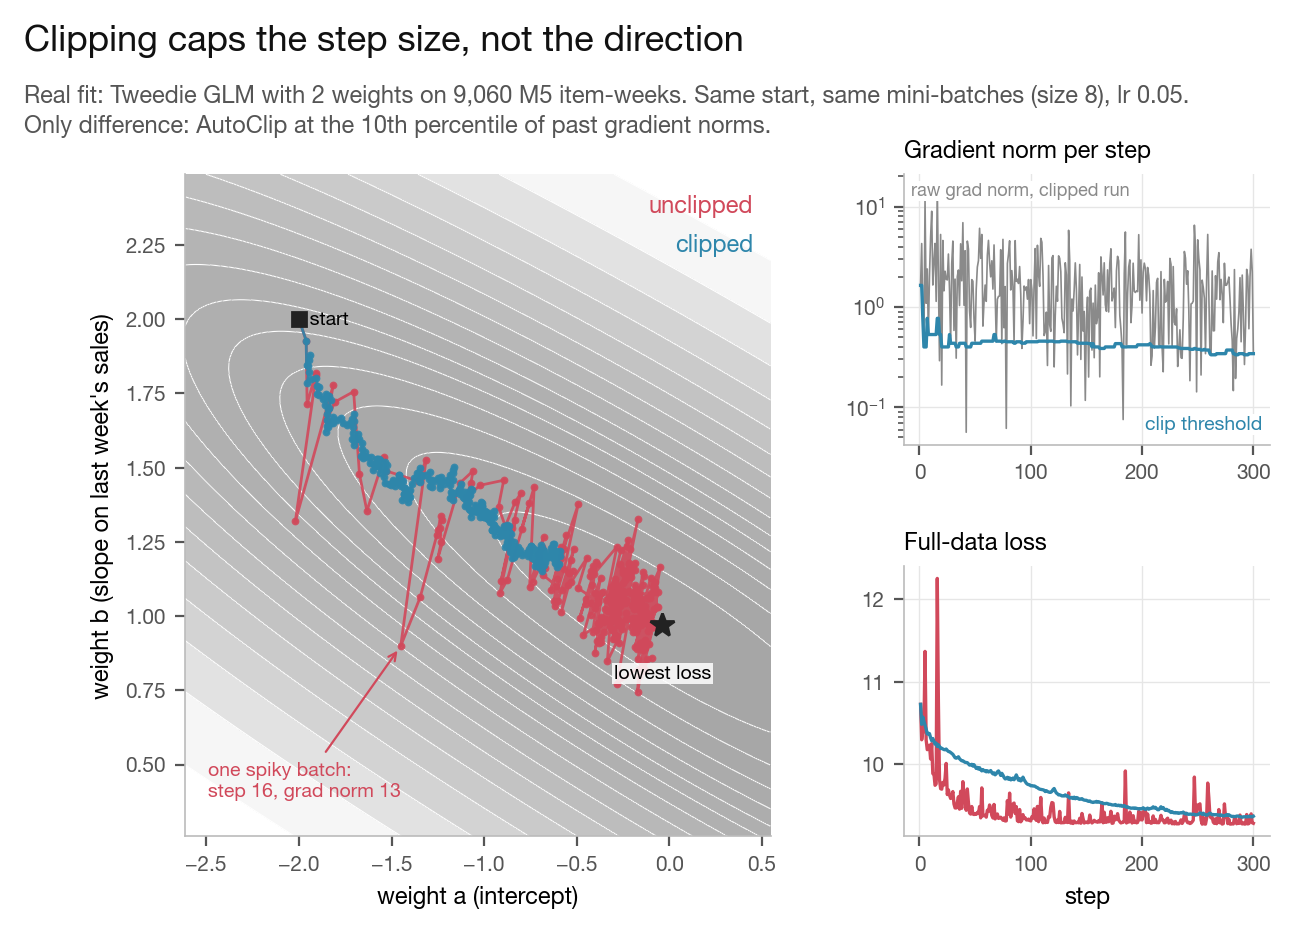

In [2]:
import json, numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
display(Image(toy.draw()[0], width=800))
tp = pd.read_parquet(os.path.join(paths.RESULTS, "toy_paths.parquet"))
T = {run: dict(step=np.hypot(g.a.diff(), g.b.diff()).max(), final=g.loss.iloc[-1], jitter=g.loss.iloc[-100:].std())
     for run, g in tp[tp.step > 0].groupby("run")}
u, c = T["unclipped"], T["clipped"]

In [3]:
ratio = max(u["step"], c["step"]) / min(u["step"], c["step"])
display(Markdown(
    f"Largest single step: {u['step']:.3f} unclipped vs {c['step']:.3f} clipped "
    f"({ratio:.1f}× {'longer' if u['step'] > c['step'] else 'shorter'} without clipping). "
    f"Loss standard deviation over the last 100 steps: {u['jitter']:.3f} unclipped vs {c['jitter']:.3f} clipped. "
    f"Final full-data loss: {u['final']:.3f} vs {c['final']:.3f}, so the "
    f"{'clipped' if c['final'] < u['final'] else 'unclipped'} run ended lower. "
    f"The toy shows what clipping does to a step; whether that matters for a full model is the next question."))

Largest single step: 0.642 unclipped vs 0.082 clipped (7.8× longer without clipping). Loss standard deviation over the last 100 steps: 0.093 unclipped vs 0.036 clipped. Final full-data loss: 9.280 vs 9.366, so the unclipped run ended lower. The toy shows what clipping does to a step; whether that matters for a full model is the next question.

## At the recipe's settings

The clipping card from notebook 03: N-HiTS with the Tweedie loss on every series, clip off vs AutoClip, everything else at the
recipe. The verdict is the one notebook 03 computed and saved.

In [4]:
off, on = results.load_run("f2_noclip"), results.load_run("f2_clip")
v = json.load(open(os.path.join(paths.RESULTS, "card_verdicts.json")))["clipping"]  # written by notebook 03
fo, fn = off["summary"]["fold_stats"][0], on["summary"]["fold_stats"][0]
spike = lambda f: f["grad_norm_max"] / f["grad_norm_median"]

In [5]:
so, sn = off["summary"], on["summary"]
display(Markdown(
    f"**Verdict on clip off: {stress.label_text(v['label'])}.** "
    f"WAPE {so['wape']:.2f} vs {sn['wape']:.2f} with AutoClip "
    f"(gap {v['wape_gap']:+.2f}; seed noise ±{data.SEED_NOISE['wape']}); "
    f"bias {so['bias']:+.1f}% vs {sn['bias']:+.1f}%. "
    f"The largest gradient was {spike(fo):,.0f}× the median without clipping and {spike(fn):,.0f}× with it. "
    f"AutoClip scaled down {fn['grad_clip_frac']:.0%} of updates; the best validation check came at step "
    + (f"{fo['best_step']:,.0f} in both runs." if fo["best_step"] == fn["best_step"] else
       f"{fo['best_step']:,.0f} without clipping and {fn['best_step']:,.0f} with it.")))

**Verdict on clip off: underfit and biased.** WAPE 49.27 vs 48.14 with AutoClip (gap +1.13; seed noise ±0.2); bias +8.1% vs +6.3%. The largest gradient was 18× the median without clipping and 141× with it. AutoClip scaled down 91% of updates; the best validation check came at step 950 without clipping and 3,000 with it.

## Under stress

Two recipe settings may limit gradient spikes: the low peak learning rate, and the short-history filter that keeps windows that
are mostly padding out of training. The stress test relaxes them one at a time, with clipping off and on, and leaves everything
else at the recipe. The three stressors were fixed before any run:

In [6]:
display(pd.DataFrame({k: {"overrides": str(o)} for k, o in experiments.STRESSORS.items()}).T)

,overrides
lr1e2,{'lr_max': 0.01}
lr3e2,{'lr_max': 0.03}
nofilter,"{'availability_threshold': [0.0, 0.0]}"


**How to read the figure.** One row per stressor. Left: gradient norm per step (red = clip off, blue = AutoClip, dashed = clip
threshold). Middle: validation loss. Right: WAPE and bias for each run and the generated outcome. A run counts as diverged when its
validation loss ends above twice its best (rule set after seeing the results, see notebook 01). When both runs diverge, the WAPE gap
only reflects which early checkpoint was restored, so it is not read as a clipping effect. Each stressor gets one of
these outcomes (from `stress.RULES`):

In [7]:
display(Markdown(stress.rules_table().rename(columns={"applies_when": "applies when"}).to_markdown(index=False)))

| outcome                                                                | applies when                                                                                                                                    | counts           |
|:-----------------------------------------------------------------------|:------------------------------------------------------------------------------------------------------------------------------------------------|:-----------------|
| clip off diverged, AutoClip did not                                    | clip off diverged and AutoClip did not                                                                                                          | for clipping     |
| clip off crashed, AutoClip finished                                    | clip off crashed (NaN loss) and AutoClip finished                                                                                               | for clipping     |
| neither diverged; the verdict on clip off was underfit, biased or both | neither run diverged, and the verdict rule (notebook 01) gives clip off underfit, biased or both                                                | for clipping     |
| both runs diverged                                                     | both runs diverged                                                                                                                              | neither          |
| both runs crashed                                                      | both runs crashed                                                                                                                               | neither          |
| only AutoClip diverged                                                 | only AutoClip diverged                                                                                                                          | against clipping |
| only AutoClip crashed                                                  | only AutoClip crashed                                                                                                                           | against clipping |
| neither diverged; the clipped forecast was worse                       | neither run diverged, clip off shows no clear effect, and the same rule applied with AutoClip as the wrong value gives underfit, biased or both | against clipping |
| no measurable difference                                               | neither run diverged and the rule finds no effect either way                                                                                    | neither          |

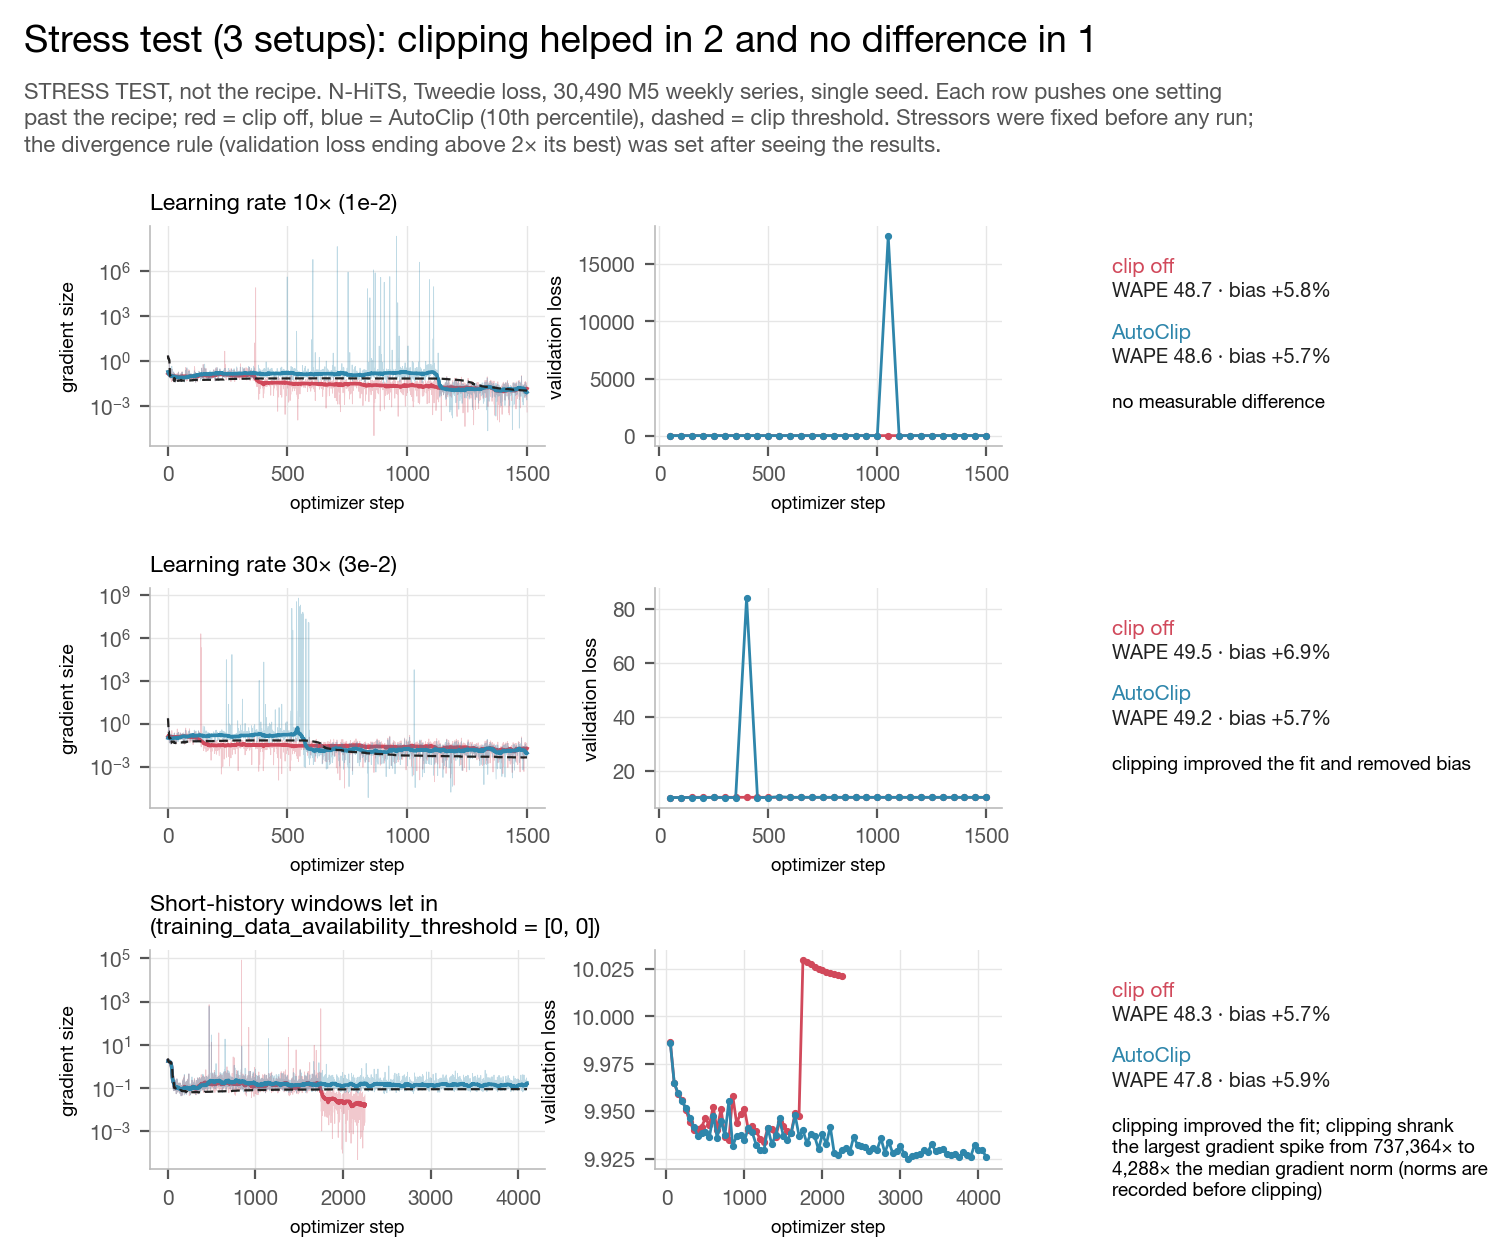

- **Learning rate 10× (1e-2)**: no measurable difference. WAPE clip off 48.74, AutoClip 48.61.
- **Learning rate 30× (3e-2)**: clipping improved the fit and removed bias. WAPE clip off 49.51, AutoClip 49.17.
- **Short-history windows let in**: clipping improved the fit; clipping shrank the largest gradient spike from 737,364× to 4,288× the median gradient norm (norms are recorded before clipping). WAPE clip off 48.33, AutoClip 47.83.

In [8]:
display(Image(stress.draw()[0], width=800))
O = json.load(open(os.path.join(paths.RESULTS, "stress_outcomes.json")))
fmt = lambda w: "crashed" if w is None else f"{w:.2f}"
wapes = lambda o: "" if "WAPE" in o["text"] else f" WAPE clip off {fmt(o['off'])}, AutoClip {fmt(o['on'])}."
display(Markdown("\n".join(f"- **{stress.LABELS[k].splitlines()[0]}**: {o['text']}.{wapes(o)}" for k, o in O.items())))

## Verdict

The verdict uses only existing labels: the clipping card's verdict on clip off, and each stressor's outcome, counted for or
against clipping as in the outcome table above. The claim **holds** if clip off is
underfit or biased at the recipe's settings and no stressor went against clipping. It **does not hold** if the recipe card shows
no clear effect and no stressor favoured clipping. Otherwise it is **mixed**. The WAPE and bias numbers above are not used by
this rule. The rule is `stress.conclusion` in `m5knobs/figures/stress.py`.

In [9]:
display(Markdown(f"{stress.headline(O)}.\n\n" + stress.conclusion(v["label"], O)))

Stress test (3 setups): clipping helped in 2 and no difference in 1.

- At the recipe's settings, the card's verdict on clip off: underfit and biased.
- Learning rate 10× (1e-2): no measurable difference.
- Learning rate 30× (3e-2): neither diverged; the verdict on clip off was underfit and biased.
- Short-history windows let in: neither diverged; the verdict on clip off was underfit.
- Verdict on the claim: **holds** (recipe card: underfit and biased; in favour of clipping: clip off scored worse under the 30× learning rate and clip off scored worse with the short-history filter off).

## What to set

- Pass `AutoClip(clip_percentile=...)` from `m5knobs.model` in the model's `callbacks`, as `Knobs` does (recipe value in notebook
  02). The alternative is Lightning's fixed `gradient_clip_val`, which needs a threshold guessed in advance.
- Record the gradient norm per step (AutoClip does this even with clipping off) and look at its largest value relative to its
  median. That ratio is the quickest check for spiky batches.
- If you raise the learning rate or relax the short-history filter, re-run with clipping on and off and compare validation loss
  curves, as in the stress test above.

Next: [05 · Deep learning vs LightGBM](05_dl_vs_lightgbm.ipynb).